In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import seaborn as sns
import scipy.stats as stats

In [11]:
filepath = "C://Users//dayee//OneDrive//Documents//Analytix Labs//Python//Case studies//Case Study 3 - Insurance Claims Case Study//"
claim_df = pd.read_csv(filepath + "claims.csv")
cust_df = pd.read_csv(filepath + "cust_demographics.csv")

In [12]:
claim_df.head()

,claim_id,customer_id,incident_cause,claim_date,claim_area,police_report,claim_type,claim_amount,total_policy_claims,fraudulent
0,54004764,21868593,Driver error,11/27/2017,Auto,No,Material only,$2980,1.0,No
1,33985796,75740424,Crime,10/03/2018,Home,Unknown,Material only,$2980,3.0,No
2,53522022,30308357,Other driver error,02/02/2018,Auto,No,Material only,$3369.5,1.0,Yes
3,13015401,47830476,Natural causes,06/17/2018,Auto,No,Material only,$1680,1.0,No
4,22890252,19269962,Crime,01/13/2018,Auto,No,Material only,$2680,1.0,No


In [13]:
claim_df.shape

(1100, 10)

In [14]:
cust_df.head()

,CUST_ID,gender,DateOfBirth,State,Contact,Segment
0,21868593,Female,12-Jan-79,VT,789-916-8172,Platinum
1,75740424,Female,13-Jan-70,ME,265-543-1264,Silver
2,30308357,Female,11-Mar-84,TN,798-631-4758,Silver
3,47830476,Female,01-May-86,MA,413-187-7945,Silver
4,19269962,Male,13-May-77,NV,956-871-8691,Gold


In [15]:
cust_df.shape

(1085, 6)

In [16]:
#Import claims_data.csv and cust_data.csv which is provided to you and
#combine the two datasets appropriately to create a 360-degree view of
#the data. Use the same for the subsequent questions.

In [17]:
df = pd.merge(left = cust_df,
              right = claim_df,
              left_on = ['CUST_ID'],
              right_on = 'customer_id',
              how = 'left')
df.head()

,CUST_ID,gender,DateOfBirth,State,Contact,Segment,claim_id,customer_id,incident_cause,claim_date,claim_area,police_report,claim_type,claim_amount,total_policy_claims,fraudulent
0,21868593,Female,12-Jan-79,VT,789-916-8172,Platinum,54004764.0,21868593.0,Driver error,11/27/2017,Auto,No,Material only,$2980,1.0,No
1,75740424,Female,13-Jan-70,ME,265-543-1264,Silver,33985796.0,75740424.0,Crime,10/03/2018,Home,Unknown,Material only,$2980,3.0,No
2,30308357,Female,11-Mar-84,TN,798-631-4758,Silver,53522022.0,30308357.0,Other driver error,02/02/2018,Auto,No,Material only,$3369.5,1.0,Yes
3,30308357,Female,11-Mar-84,TN,798-631-4758,Silver,63017412.0,30308357.0,Driver error,04/04/2018,Auto,No,Material only,$1950,6.0,No
4,47830476,Female,01-May-86,MA,413-187-7945,Silver,13015401.0,47830476.0,Natural causes,06/17/2018,Auto,No,Material only,$1680,1.0,No


In [18]:
#Perform a data audit for the datatypes and find out if there are any
#mismatch within the current datatypes of the columns and their
#business significance.

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CUST_ID              1092 non-null   int64  
 1   gender               1092 non-null   object 
 2   DateOfBirth          1092 non-null   object 
 3   State                1092 non-null   object 
 4   Contact              1092 non-null   object 
 5   Segment              1092 non-null   object 
 6   claim_id             1085 non-null   float64
 7   customer_id          1085 non-null   float64
 8   incident_cause       1085 non-null   object 
 9   claim_date           1085 non-null   object 
 10  claim_area           1085 non-null   object 
 11  police_report        1085 non-null   object 
 12  claim_type           1085 non-null   object 
 13  claim_amount         1020 non-null   object 
 14  total_policy_claims  1075 non-null   float64
 15  fraudulent           1085 non-null   o

In [20]:
df['DateOfBirth'] = pd.to_datetime(df['DateOfBirth'], format = 'mixed')
df['Contact'] = df['Contact'].str.replace("-","")
df['Contact'] = df['Contact'].astype('int64')

In [21]:
df[['claim_id', 'customer_id']] = df[['claim_id', 'customer_id']].fillna(0).astype('int64')
df[['claim_id', 'customer_id']] = df[['claim_id', 'customer_id']].astype('int64')

In [22]:
df['claim_date'] = pd.to_datetime(df['claim_date'])

In [23]:
df['total_policy_claims'] = df['total_policy_claims'].fillna(0).astype('int64')
df['total_policy_claims'] = df['total_policy_claims'].astype('int64')

In [24]:
#Convert the column claim_amount to numeric. Use the appropriate
#modules/attributes to remove the $ sign.

In [25]:
df.head()

,CUST_ID,gender,DateOfBirth,State,Contact,Segment,claim_id,customer_id,incident_cause,claim_date,claim_area,police_report,claim_type,claim_amount,total_policy_claims,fraudulent
0,21868593,Female,1979-01-12,VT,7899168172,Platinum,54004764,21868593,Driver error,2017-11-27,Auto,No,Material only,$2980,1,No
1,75740424,Female,2070-01-13,ME,2655431264,Silver,33985796,75740424,Crime,2018-10-03,Home,Unknown,Material only,$2980,3,No
2,30308357,Female,1984-03-11,TN,7986314758,Silver,53522022,30308357,Other driver error,2018-02-02,Auto,No,Material only,$3369.5,1,Yes
3,30308357,Female,1984-03-11,TN,7986314758,Silver,63017412,30308357,Driver error,2018-04-04,Auto,No,Material only,$1950,6,No
4,47830476,Female,1986-05-01,MA,4131877945,Silver,13015401,47830476,Natural causes,2018-06-17,Auto,No,Material only,$1680,1,No


In [26]:
df['claim_amount'] = df['claim_amount'].str.replace('$', '')
df['claim_amount'] = df['claim_amount'].astype('float64')

In [27]:
#Of all the injury claims, some of them have gone unreported with the
#police. Create an alert flag (1,0) for all such claims.

In [28]:
def in_flag(x):
    val = 0
    if x['claim_type'] == 'Injury only' and x['police_report'] == 'No':
        val = 1
    else:
        val = 0
    return val

In [29]:
df.drop(columns = 'report_flag', inplace = True)
pos = df.columns.get_loc('police_report')
df.insert(pos+1,
          'report_flag',
          df.apply(in_flag, axis = 1))

KeyError: "['report_flag'] not found in axis"

In [ ]:
df.loc[(df['claim_type'] == 'Injury only') & (df['police_report'] == 'No')]

In [ ]:
#One customer can claim for insurance more than once and in each claim,
#multiple categories of claims can be involved. However, customer ID
#should remain unique.
#Retain the most recent observation and delete any duplicated records in
#the data based on the customer ID column.

In [ ]:
df.sort_values(by = ['claim_date'], ascending = False, inplace = True)

In [ ]:
df.drop_duplicates(subset = 'customer_id', keep = 'first', inplace = True)

In [30]:
df.reset_index(drop = True, inplace = True)
df.head()

,CUST_ID,gender,DateOfBirth,State,Contact,Segment,claim_id,customer_id,incident_cause,claim_date,claim_area,police_report,claim_type,claim_amount,total_policy_claims,fraudulent
0,21868593,Female,1979-01-12,VT,7899168172,Platinum,54004764,21868593,Driver error,2017-11-27,Auto,No,Material only,2980.0,1,No
1,75740424,Female,2070-01-13,ME,2655431264,Silver,33985796,75740424,Crime,2018-10-03,Home,Unknown,Material only,2980.0,3,No
2,30308357,Female,1984-03-11,TN,7986314758,Silver,53522022,30308357,Other driver error,2018-02-02,Auto,No,Material only,3369.5,1,Yes
3,30308357,Female,1984-03-11,TN,7986314758,Silver,63017412,30308357,Driver error,2018-04-04,Auto,No,Material only,1950.0,6,No
4,47830476,Female,1986-05-01,MA,4131877945,Silver,13015401,47830476,Natural causes,2018-06-17,Auto,No,Material only,1680.0,1,No


In [31]:
#Check for missing values and impute the missing values with an
#appropriate value. (mean for continuous and mode for categorical)

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   CUST_ID              1092 non-null   int64         
 1   gender               1092 non-null   object        
 2   DateOfBirth          1092 non-null   datetime64[ns]
 3   State                1092 non-null   object        
 4   Contact              1092 non-null   int64         
 5   Segment              1092 non-null   object        
 6   claim_id             1092 non-null   int64         
 7   customer_id          1092 non-null   int64         
 8   incident_cause       1085 non-null   object        
 9   claim_date           1085 non-null   datetime64[ns]
 10  claim_area           1085 non-null   object        
 11  police_report        1085 non-null   object        
 12  claim_type           1085 non-null   object        
 13  claim_amount         1020 non-nul

In [33]:
df.isna().sum()

CUST_ID                 0
gender                  0
DateOfBirth             0
State                   0
Contact                 0
Segment                 0
claim_id                0
customer_id             0
incident_cause          7
claim_date              7
claim_area              7
police_report           7
claim_type              7
claim_amount           72
total_policy_claims     0
fraudulent              7
dtype: int64

In [34]:
num_df = df.select_dtypes(exclude = ['object', 'datetime64[ns]'])
cat_df = df.select_dtypes(include = ['object'])

In [35]:
num_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CUST_ID              1092 non-null   int64  
 1   Contact              1092 non-null   int64  
 2   claim_id             1092 non-null   int64  
 3   customer_id          1092 non-null   int64  
 4   claim_amount         1020 non-null   float64
 5   total_policy_claims  1092 non-null   int64  
dtypes: float64(1), int64(5)
memory usage: 51.3 KB


In [36]:
cat_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   gender          1092 non-null   object
 1   State           1092 non-null   object
 2   Segment         1092 non-null   object
 3   incident_cause  1085 non-null   object
 4   claim_area      1085 non-null   object
 5   police_report   1085 non-null   object
 6   claim_type      1085 non-null   object
 7   fraudulent      1085 non-null   object
dtypes: object(8)
memory usage: 68.4+ KB


In [37]:
date_df = df.select_dtypes(include = ['datetime64[ns]'])
date_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   DateOfBirth  1092 non-null   datetime64[ns]
 1   claim_date   1085 non-null   datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 17.2 KB


In [38]:
def missing_num(x):
    val = np.mean(x)
    x = x.fillna(val)
    return x

In [39]:
num_df = num_df.apply(missing_num)

In [40]:
def missing_val(x):
    val = x.mode()[0]
    x = x.fillna(val)
    return x

In [41]:
cat_df = cat_df.apply(missing_val)

In [42]:
clean_df = pd.concat([cat_df, num_df, date_df], axis = 1)
clean_df.head()

,gender,State,Segment,incident_cause,claim_area,police_report,claim_type,fraudulent,CUST_ID,Contact,claim_id,customer_id,claim_amount,total_policy_claims,DateOfBirth,claim_date
0,Female,VT,Platinum,Driver error,Auto,No,Material only,No,21868593,7899168172,54004764,21868593,2980.0,1,1979-01-12,2017-11-27
1,Female,ME,Silver,Crime,Home,Unknown,Material only,No,75740424,2655431264,33985796,75740424,2980.0,3,2070-01-13,2018-10-03
2,Female,TN,Silver,Other driver error,Auto,No,Material only,Yes,30308357,7986314758,53522022,30308357,3369.5,1,1984-03-11,2018-02-02
3,Female,TN,Silver,Driver error,Auto,No,Material only,No,30308357,7986314758,63017412,30308357,1950.0,6,1984-03-11,2018-04-04
4,Female,MA,Silver,Natural causes,Auto,No,Material only,No,47830476,4131877945,13015401,47830476,1680.0,1,1986-05-01,2018-06-17


In [43]:
"""
Calculate the age of customers in years. Based on the age, categorize the
customers according to the below criteria
Children < 18
Youth 18-30
Adult 30-60
Senior > 60
"""

'\nCalculate the age of customers in years. Based on the age, categorize the\ncustomers according to the below criteria\nChildren < 18\nYouth 18-30\nAdult 30-60\nSenior > 60\n'

In [44]:
clean_df.drop(columns = 'Age', inplace = True)

KeyError: "['Age'] not found in axis"

In [45]:
clean_df.loc[clean_df['DateOfBirth'] > pd.Timestamp.today(), 'DateOfBirth'] = clean_df.loc[clean_df['DateOfBirth'] > pd.Timestamp.today(), 'DateOfBirth'] - pd.DateOffset(years = 100)

In [46]:
clean_df.head()

,gender,State,Segment,incident_cause,claim_area,police_report,claim_type,fraudulent,CUST_ID,Contact,claim_id,customer_id,claim_amount,total_policy_claims,DateOfBirth,claim_date
0,Female,VT,Platinum,Driver error,Auto,No,Material only,No,21868593,7899168172,54004764,21868593,2980.0,1,1979-01-12,2017-11-27
1,Female,ME,Silver,Crime,Home,Unknown,Material only,No,75740424,2655431264,33985796,75740424,2980.0,3,1970-01-13,2018-10-03
2,Female,TN,Silver,Other driver error,Auto,No,Material only,Yes,30308357,7986314758,53522022,30308357,3369.5,1,1984-03-11,2018-02-02
3,Female,TN,Silver,Driver error,Auto,No,Material only,No,30308357,7986314758,63017412,30308357,1950.0,6,1984-03-11,2018-04-04
4,Female,MA,Silver,Natural causes,Auto,No,Material only,No,47830476,4131877945,13015401,47830476,1680.0,1,1986-05-01,2018-06-17


In [47]:
clean_df['Age'] = (pd.Timestamp.today() - clean_df['DateOfBirth']).dt.days//365

In [48]:
clean_df.head()

,gender,State,Segment,incident_cause,claim_area,police_report,claim_type,fraudulent,CUST_ID,Contact,claim_id,customer_id,claim_amount,total_policy_claims,DateOfBirth,claim_date,Age
0,Female,VT,Platinum,Driver error,Auto,No,Material only,No,21868593,7899168172,54004764,21868593,2980.0,1,1979-01-12,2017-11-27,47
1,Female,ME,Silver,Crime,Home,Unknown,Material only,No,75740424,2655431264,33985796,75740424,2980.0,3,1970-01-13,2018-10-03,56
2,Female,TN,Silver,Other driver error,Auto,No,Material only,Yes,30308357,7986314758,53522022,30308357,3369.5,1,1984-03-11,2018-02-02,42
3,Female,TN,Silver,Driver error,Auto,No,Material only,No,30308357,7986314758,63017412,30308357,1950.0,6,1984-03-11,2018-04-04,42
4,Female,MA,Silver,Natural causes,Auto,No,Material only,No,47830476,4131877945,13015401,47830476,1680.0,1,1986-05-01,2018-06-17,39


In [49]:
clean_df['Age_Group'] = clean_df['Age'].map(lambda x: "Youth" if x < 18 else "Adult" if x >= 30 and x <= 60 else "Senior")

In [50]:
#What is the average amount claimed by the customers from various segments?
avg_seg_amt = clean_df.pivot_table(index = 'Segment', values = 'claim_amount', aggfunc = 'mean').reset_index()
avg_seg_amt

,Segment,claim_amount
0,Gold,12828.669339
1,Platinum,12342.985657
2,Silver,12210.651346


In [51]:
#What is the total claim amount based on incident cause for all the claims
#that have been done at least 20 days prior to 1st of October, 2018.

In [52]:
d = datetime.datetime.strptime('2018-10-01', '%Y-%m-%d')

In [53]:
cl1 = clean_df.loc[(clean_df['claim_date'] - d).dt.days > 20, ['claim_amount']]

In [54]:
cl1['claim_amount'].sum()

np.float64(267808.2254901961)

In [55]:
#How many adults from TX, DE and AK claimed insurance for driver
#related issues and causes?

In [56]:
clean_df.head()

,gender,State,Segment,incident_cause,claim_area,police_report,claim_type,fraudulent,CUST_ID,Contact,claim_id,customer_id,claim_amount,total_policy_claims,DateOfBirth,claim_date,Age,Age_Group
0,Female,VT,Platinum,Driver error,Auto,No,Material only,No,21868593,7899168172,54004764,21868593,2980.0,1,1979-01-12,2017-11-27,47,Adult
1,Female,ME,Silver,Crime,Home,Unknown,Material only,No,75740424,2655431264,33985796,75740424,2980.0,3,1970-01-13,2018-10-03,56,Adult
2,Female,TN,Silver,Other driver error,Auto,No,Material only,Yes,30308357,7986314758,53522022,30308357,3369.5,1,1984-03-11,2018-02-02,42,Adult
3,Female,TN,Silver,Driver error,Auto,No,Material only,No,30308357,7986314758,63017412,30308357,1950.0,6,1984-03-11,2018-04-04,42,Adult
4,Female,MA,Silver,Natural causes,Auto,No,Material only,No,47830476,4131877945,13015401,47830476,1680.0,1,1986-05-01,2018-06-17,39,Adult


In [57]:
clean_df.loc[(clean_df['State'].isin(['TX', 'DE', 'AK'])) & (clean_df['Age_Group'] == 'Adult') & (clean_df['incident_cause'].isin(['Driver error', 'Other driver error'])), ['Age_Group']].count()

Age_Group    29
dtype: int64

In [58]:
#Draw a pie chart between the aggregated value of claim amount based
#on gender and segment. Represent the claim amount as a percentage on
#the pie chart.

In [59]:
clean_df.head()

,gender,State,Segment,incident_cause,claim_area,police_report,claim_type,fraudulent,CUST_ID,Contact,claim_id,customer_id,claim_amount,total_policy_claims,DateOfBirth,claim_date,Age,Age_Group
0,Female,VT,Platinum,Driver error,Auto,No,Material only,No,21868593,7899168172,54004764,21868593,2980.0,1,1979-01-12,2017-11-27,47,Adult
1,Female,ME,Silver,Crime,Home,Unknown,Material only,No,75740424,2655431264,33985796,75740424,2980.0,3,1970-01-13,2018-10-03,56,Adult
2,Female,TN,Silver,Other driver error,Auto,No,Material only,Yes,30308357,7986314758,53522022,30308357,3369.5,1,1984-03-11,2018-02-02,42,Adult
3,Female,TN,Silver,Driver error,Auto,No,Material only,No,30308357,7986314758,63017412,30308357,1950.0,6,1984-03-11,2018-04-04,42,Adult
4,Female,MA,Silver,Natural causes,Auto,No,Material only,No,47830476,4131877945,13015401,47830476,1680.0,1,1986-05-01,2018-06-17,39,Adult


In [60]:
agg1 = clean_df.groupby(by = ['gender', 'Segment']).agg(AvgClaim = ('claim_amount', 'mean'))
agg1.reset_index(inplace = True)
agg1

,gender,Segment,AvgClaim
0,Female,Gold,12338.405894
1,Female,Platinum,12278.100263
2,Female,Silver,11543.541083
3,Male,Gold,13242.028715
4,Male,Platinum,12416.598326
5,Male,Silver,12823.080440


In [61]:
agg_labels = agg1['gender'] + '-' + agg1['Segment']
agg_labels

0        Female-Gold
1    Female-Platinum
2      Female-Silver
3          Male-Gold
4      Male-Platinum
5        Male-Silver
dtype: object

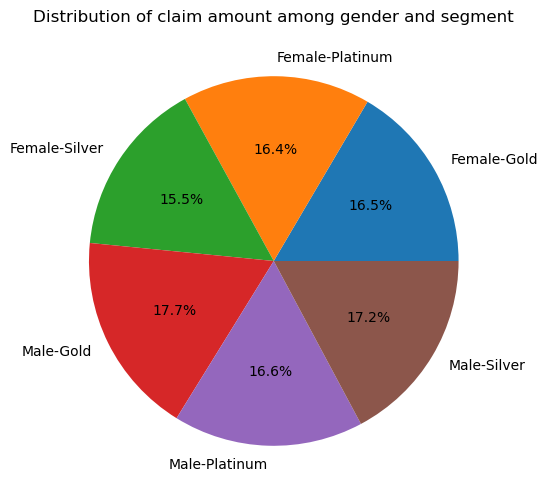

In [62]:
plt.figure(figsize = (6,6))
plt.pie(agg1['AvgClaim'],
        labels = agg_labels,
        autopct = '%1.1f%%')
plt.title("Distribution of claim amount among gender and segment")
plt.show()

In [63]:
#Among males and females, which gender had claimed the most for any
#type of driver related issues? E.g. This metric can be compared using a
#bar chart

In [64]:
df2 = clean_df.loc[clean_df['incident_cause'].isin(['Driver error', 'Other driver error']), ['gender', 'incident_cause']].reset_index()
df2.drop(columns = 'index', inplace = True)
df2.head()

,gender,incident_cause
0,Female,Driver error
1,Female,Other driver error
2,Female,Driver error
3,Male,Other driver error
4,Male,Driver error


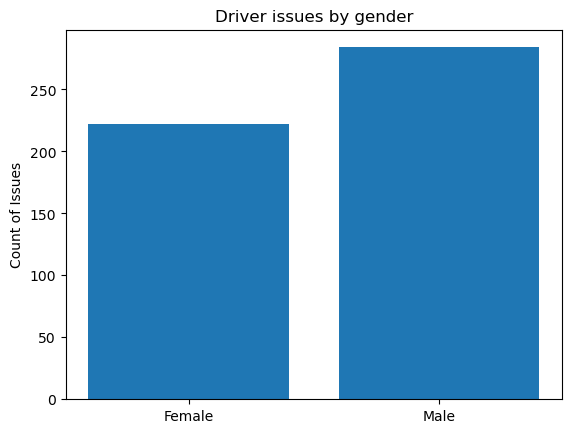

In [65]:
agg3 = df2.pivot_table(index = 'gender', values = 'gender', aggfunc = 'count').reset_index()

plt.bar(data = agg3,
        x = agg3.columns[0],
        height = agg3.columns[1])
plt.title('Driver issues by gender')
plt.ylabel('Count of Issues')
plt.show()

In [66]:
#Which age group had the maximum fraudulent policy claims? Visualize
#it on a bar chart.

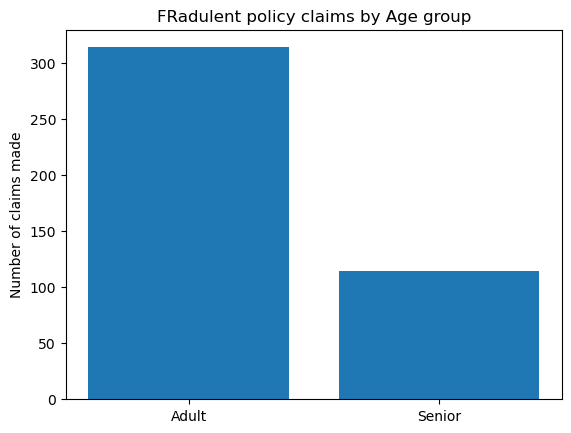

In [67]:
df4 = clean_df.loc[clean_df['fraudulent'] == 'Yes', ['total_policy_claims', 'Age_Group']]
agg4 = df4.pivot_table(index = 'Age_Group', values = 'total_policy_claims', aggfunc = 'sum').reset_index()
plt.title("FRadulent policy claims by Age group")
plt.ylabel("Number of claims made")
plt.bar(data = agg4,
        x = agg4.columns[0],
        height = agg4.columns[1])
plt.show()

In [68]:
#Visualize the monthly trend of the total amount that has been claimed
#by the customers. Ensure that on the “month” axis, the month is in a
#chronological order not alphabetical order.

In [69]:
clean_df.head()

,gender,State,Segment,incident_cause,claim_area,police_report,claim_type,fraudulent,CUST_ID,Contact,claim_id,customer_id,claim_amount,total_policy_claims,DateOfBirth,claim_date,Age,Age_Group
0,Female,VT,Platinum,Driver error,Auto,No,Material only,No,21868593,7899168172,54004764,21868593,2980.0,1,1979-01-12,2017-11-27,47,Adult
1,Female,ME,Silver,Crime,Home,Unknown,Material only,No,75740424,2655431264,33985796,75740424,2980.0,3,1970-01-13,2018-10-03,56,Adult
2,Female,TN,Silver,Other driver error,Auto,No,Material only,Yes,30308357,7986314758,53522022,30308357,3369.5,1,1984-03-11,2018-02-02,42,Adult
3,Female,TN,Silver,Driver error,Auto,No,Material only,No,30308357,7986314758,63017412,30308357,1950.0,6,1984-03-11,2018-04-04,42,Adult
4,Female,MA,Silver,Natural causes,Auto,No,Material only,No,47830476,4131877945,13015401,47830476,1680.0,1,1986-05-01,2018-06-17,39,Adult


In [70]:
pos = clean_df.columns.get_loc('claim_date')
clean_df.insert(pos+1,
                'month',
                df['claim_date'].dt.month)

In [71]:
pos2 = clean_df.columns.get_loc('month')
clean_df.insert(pos2+1,
                'year',
                df['claim_date'].dt.year)

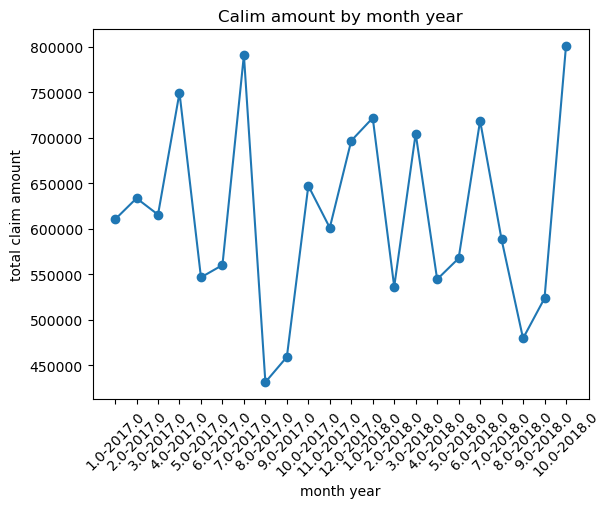

In [72]:
agg5 = clean_df.groupby(by = ['year', 'month']).agg(TotClaim = ('claim_amount', 'sum')).reset_index()
agg5['month-year'] = agg5['month'].astype(str) + '-' + agg5['year'].astype(str)

plt.plot(agg5['month-year'], agg5['TotClaim'], marker = 'o')
plt.title('Calim amount by month year')
plt.xlabel('month year')
plt.ylabel('total claim amount')
plt.xticks(rotation = 45)
plt.show()

In [73]:
#What is the average claim amount for gender and age categories and
#suitably represent the above using a facetted bar chart, one facet that
#represents fraudulent claims and the other for non-fraudulent claims.

In [74]:
df5 = clean_df[['gender', 'Age', 'claim_amount', 'fraudulent']]
agg6 = df5.pivot_table(index = ['gender', 'Age'], columns = 'fraudulent', values = 'claim_amount', aggfunc = 'mean')
agg6

fraudulent            No           Yes
gender Age                            
Female 26    8810.000000   2553.000000
       27   10763.460172   2108.333333
       28   12780.480086  15893.000000
       29    9185.548669   5719.893791
       30   12787.500000   7107.840686
...                  ...           ...
Male   62    6747.692308   2558.750000
       63    8945.000000  15078.416667
       64   16717.262527  44367.000000
       65   10783.076923  20165.250000
       66   16643.333333           NaN

[82 rows x 2 columns]

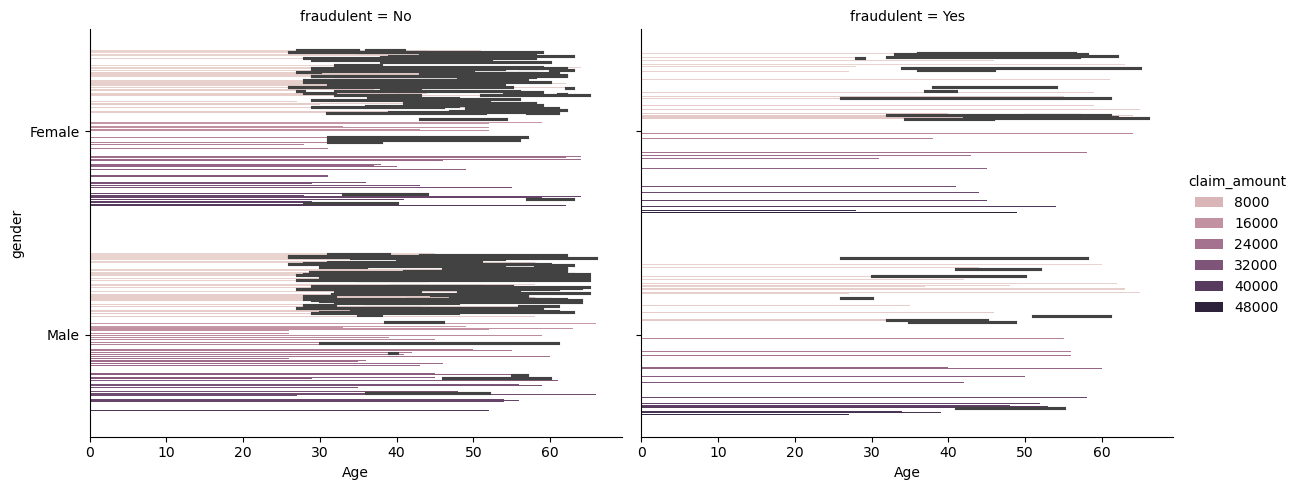

In [75]:
sns.catplot(data = df5,
            x = 'Age',
            y = 'gender',
            hue = 'claim_amount',
            col = 'fraudulent',
            kind = 'bar',
            height = 5,
            aspect = 1.2)
plt.show()

In [76]:
#Is there any similarity in the amount claimed by males and females?

In [77]:
# H0: there is similarity in claim amount between males and females
# HA: there is no similarity
# CI: 0.95, alpha: 0.05

In [78]:
female = clean_df.loc[clean_df['gender'] == 'Female', 'claim_amount']
male = clean_df.loc[clean_df['gender'] == 'Male', 'claim_amount']

In [79]:
stats.ttest_ind(a = female, b = male)

TtestResult(statistic=np.float64(-0.9737504539933243), pvalue=np.float64(0.3303965009812033), df=np.float64(1090.0))

In [80]:
# Since the p value is hgher than 5%, fail; to reject the H0
# We conclude that there is not much difference in claim amounts among males and females

In [81]:
#Is there any relationship between age category and segment?

In [82]:
# H0: there is no relationship between age category and segment
# Ha: there exists a relationship
# CI: 0.95, alpha: 0.05

In [83]:
clean_df[['Age_Group', 'Segment']]

,Age_Group,Segment
0,Adult,Platinum
1,Adult,Silver
2,Adult,Silver
3,Adult,Silver
4,Adult,Silver
...,...,...
1087,Adult,Platinum
1088,Senior,Silver
1089,Adult,Gold
1090,Senior,Silver


In [84]:
obs_freq = pd.crosstab(clean_df.Age_Group, clean_df.Segment)
obs_freq

Segment,Gold,Platinum,Silver
Age_Group,,,
Adult,294,281,268
Senior,82,84,83


In [85]:
stats.chi2_contingency(obs_freq)

Chi2ContingencyResult(statistic=np.float64(0.3624064815394863), pvalue=np.float64(0.8342657846439515), dof=2, expected_freq=array([[290.26373626, 281.77197802, 270.96428571],
       [ 85.73626374,  83.22802198,  80.03571429]]))

In [86]:
# since p val > alpha, we fail to reject H0
#There is no relationship between age category and segment

In [87]:
#The current year has shown a significant rise in claim amounts as
#compared to 2016-17 fiscal average which was $10,000.

In [88]:
# H0:claim amount has not increased
# Ha: claim amount has increased
# CI: 0.95, alpha: 0.05

In [89]:
pop_mean = 10000
current_claim_year = clean_df.loc[clean_df['year'] == 2018, ['claim_amount']]

In [90]:
stats.ttest_1samp(current_claim_year['claim_amount'], pop_mean)

TtestResult(statistic=np.float64(4.421788475402985), pvalue=np.float64(1.2086880225728461e-05), df=np.int64(486))

In [91]:
# p val < alpha, we fail to reject Ha
# Therefore we conclude that theclaim amount has increased

In [92]:
#Is there any difference between age groups and insurance claims?

In [93]:
# H0: there is no difference
# Ha: there is a difference
# CI: 0.95, alpha:0.05

In [94]:
cust_seg_1 = clean_df.loc[clean_df['Age_Group'] == 'Adult', ['claim_amount']]
cust_seg_2 = clean_df.loc[clean_df['Age_Group'] == 'Senior', ['claim_amount']]

In [95]:
stats.f_oneway(cust_seg_1, cust_seg_2)

F_onewayResult(statistic=array([2.81424848]), pvalue=array([0.09371733]))

In [96]:
# since p val > alpha, we fail to reject H0:
# we conclude tha there is a difference between age groups and insurance claims

In [97]:
#Is there any relationship between total number of policy claims and the
#claimed amount?

In [98]:
clean_df[['total_policy_claims', 'claim_amount']].corr()

,total_policy_claims,claim_amount
total_policy_claims,1.000000,-0.018595
claim_amount,-0.018595,1.000000


In [99]:
# They are negatively correlated

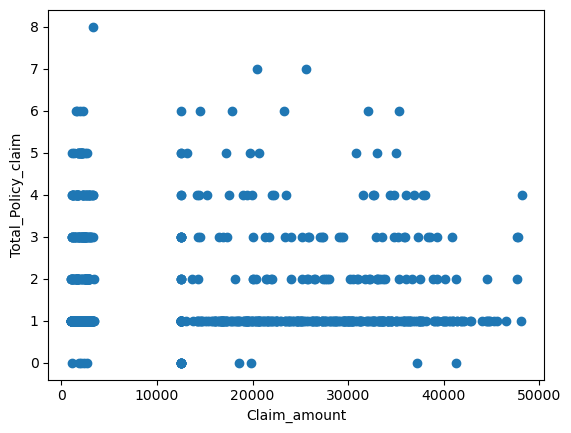

In [106]:
plt.scatter(y = clean_df.total_policy_claims, x = clean_df.claim_amount)
plt.ylabel('Total_Policy_claim')
plt.xlabel('Claim_amount')
plt.show()